# **Klasifikasi resiko penyakit jantung menggunakan logistic regression**

# **Bussines Understanding**

## **1.1 Latar Belakang**

Sebuah institusi kesehatan kardiologi ingin membangun kecerdasan buatan berbasis Machine Learning untuk mendeteksi dan memprediksi tingkat risiko pasien mengalami penyakit jantung koroner (Coronary Heart Disease / CHD) secara otomatis, berdasarkan rekam medis klinis pasien tanpa harus melalui estimasi manual yang kompleks.

## **1.2 Tujuan**

Mmembangun kecedasan buatan atau machine learning untuk mendeteksi dan memprediksi tingkat risiko pasien mengalami penyakit jantung koroner.

## **1.3 Masalah**

Terlalu banyak data dari pasien sehingga dalam menentukan tingkat risiko pasien mengalami penyakit jantung koroner, sehingga dalam memprediksi dapat kesalah dan membutuhkan waktu yang lama.

## **1.4 Solusi**

Membuat machine learning model untuk memprediksi pasien mengalami penyakit jantung koroner dengan mmenggunakan model logistic regression.


## **1.5 Deskripsi Kolom**

- male: Jenis kelamin pasien (Kategori biner: 1 untuk pria, 0 untuk wanita).
- age: Usia pasien (satuan: Tahun).
- education: Tingkat pendidikan pasien (Kategori integer: 1 sampai 4).
- currentSmoker: Status perokok aktif (Kategori biner: 1 ya, 0 tidak).
- cigsPerDay: Jumlah rokok yang dihisap per hari (satuan: Batang rokok).
- BPMeds: Penggunaan obat tekanan darah (Kategori biner: 1 ya, 0 tidak).
- prevalentStroke: Riwayat stroke sebelumnya (Kategori biner: 1 ya, 0 tidak).
- prevalentHyp: Riwayat hipertensi (Kategori biner: 1 ya, 0 tidak).
- diabetes: Riwayat penyakit diabetes (Kategori biner: 1 ya, 0 tidak).
- totChol: Kadar kolesterol total (satuan: mg/dL).
- sysBP: Tekanan darah sistolik (satuan: mmHg)
- diaBP: Tekanan darah diastolik (satuan: mmHg)
- BMI: Indeks Massa Tubuh / Body Mass Index (satuan: kg/m ).
- heartRate: Denyut jantung (satuan: Detak per menit / bpm).
- glucose: Kadar glukosa darah (satuan: mg/dL).
- TenYearCHD


# **2. Data Preparation**


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import tkinter as tk
from tkinter import ttk
from tkinter import messagebox

In [3]:
df = pd.read_csv('../dataset/framingham.csv')

In [4]:
df.head()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [5]:
print('Jumlah Baris pada dataset :', df.shape[0])
print('=========================================')
print('Jumlah Kolom pada dataset :', df.shape[1])
print('=========================================')
print('Jumlah total data pada dataset :', df.size)


Jumlah Baris pada dataset : 4238
Jumlah Kolom pada dataset : 16
Jumlah total data pada dataset : 67808


In [6]:
df.size

67808

In [7]:
df.info()
print('==============================================================')
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4238 non-null   int64  
 1   age              4238 non-null   int64  
 2   education        4133 non-null   float64
 3   currentSmoker    4238 non-null   int64  
 4   cigsPerDay       4209 non-null   float64
 5   BPMeds           4185 non-null   float64
 6   prevalentStroke  4238 non-null   int64  
 7   prevalentHyp     4238 non-null   int64  
 8   diabetes         4238 non-null   int64  
 9   totChol          4188 non-null   float64
 10  sysBP            4238 non-null   float64
 11  diaBP            4238 non-null   float64
 12  BMI              4219 non-null   float64
 13  heartRate        4237 non-null   float64
 14  glucose          3850 non-null   float64
 15  TenYearCHD       4238 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 529.9 KB


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
count,4238.000000,4238.000000,4133.000000,4238.000000,4209.000000,4185.000000,4238.000000,4238.000000,4238.000000,4188.000000,4238.000000,4238.000000,4219.000000,4237.000000,3850.000000,4238.000000
mean,0.429212,49.584946,1.978950,0.494101,9.003089,0.029630,0.005899,0.310524,0.025720,236.721585,132.352407,82.893464,25.802008,75.878924,81.966753,0.151958
std,0.495022,8.572160,1.019791,0.500024,11.920094,0.169584,0.076587,0.462763,0.158316,44.590334,22.038097,11.910850,4.080111,12.026596,23.959998,0.359023
min,0.000000,32.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,107.000000,83.500000,48.000000,15.540000,44.000000,40.000000,0.000000
25%,0.000000,42.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,206.000000,117.000000,75.000000,23.070000,68.000000,71.000000,0.000000
50%,0.000000,49.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,234.000000,128.000000,82.000000,25.400000,75.000000,78.000000,0.000000
75%,1.000000,56.000000,3.000000,1.000000,20.000000,0.000000,0.000000,1.000000,0.000000,263.000000,144.000000,89.875000,28.040000,83.000000,87.000000,0.000000
max,1.000000,70.000000,4.000000,1.000000,70.000000,1.000000,1.000000,1.000000,1.000000,696.000000,295.000000,142.500000,56.800000,143.000000,394.000000,1.000000


In [8]:
df.isnull().sum().sum()

np.int64(645)

In [9]:
df.duplicated().sum().sum()

np.int64(0)

# **3. Exploratory Data Analysis**

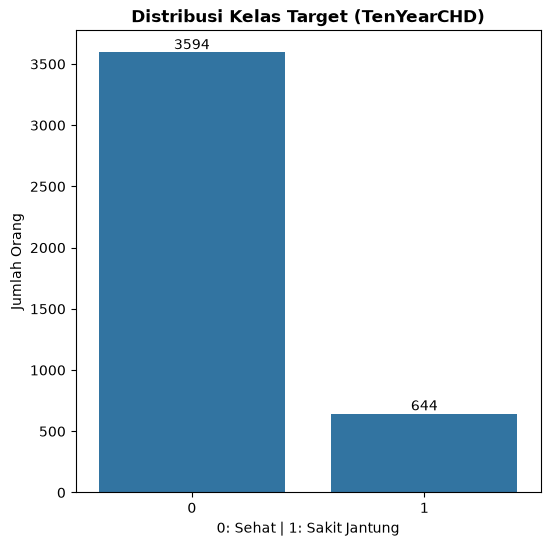

In [45]:
plt.figure(figsize=(6, 6))

ax = sns.countplot(x='TenYearCHD', data=df)
plt.title('Distribusi Kelas Target (TenYearCHD)', fontsize=12, fontweight='bold')
plt.xlabel('0: Sehat | 1: Sakit Jantung')
plt.ylabel('Jumlah Orang')

# for p in ax.patches:
#     ax.annotate(f'{p.get_height()}', (p.get_x() + 0.3, p.get_height() + 50))

ax.bar_label(ax.containers[0])
plt.show()

Terlihat dengan jelas bahwa adanya data imbalanced pada kolom target

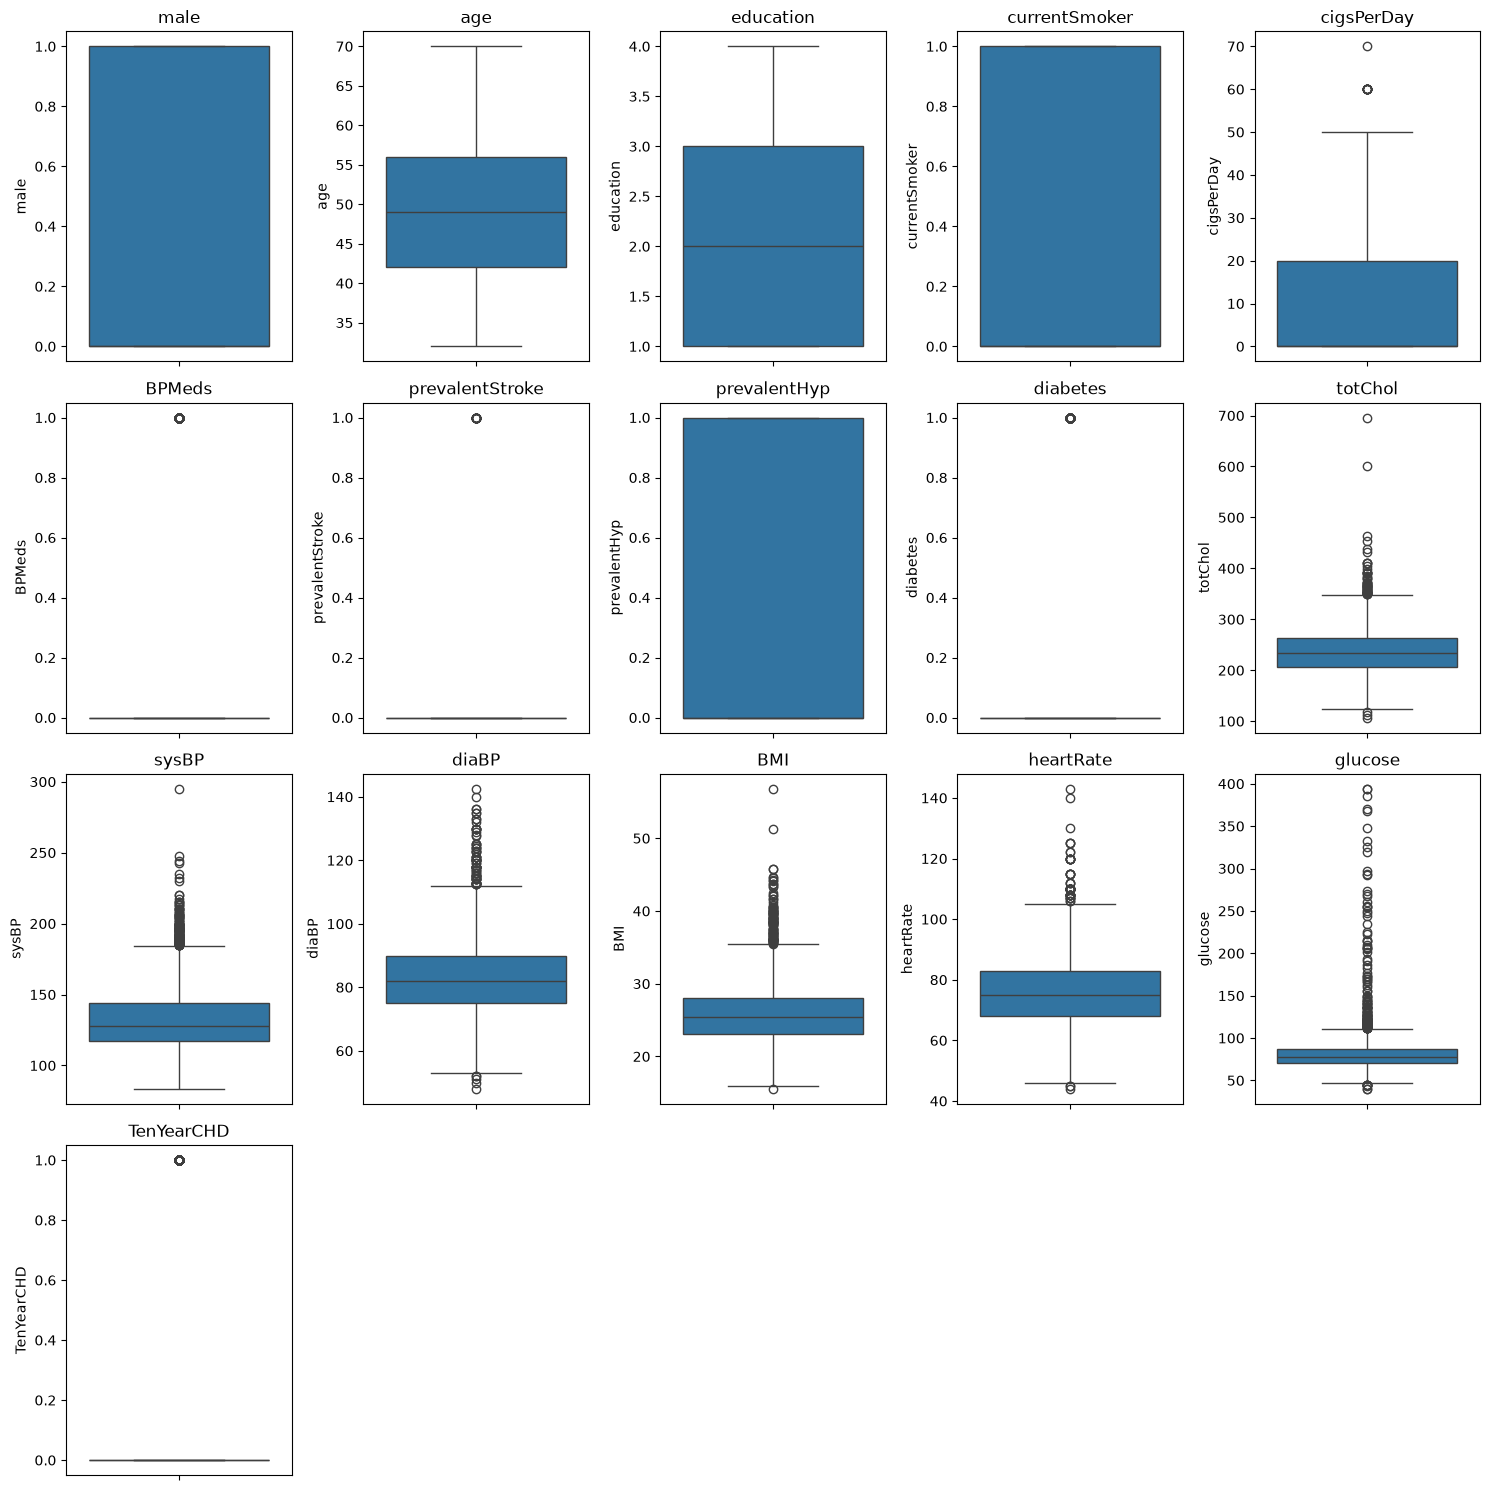

In [11]:
kolom = df.select_dtypes(include=['number'])

plt.figure(figsize=(15,15))

for i, col in enumerate(kolom, start=1):
    plt.subplot(4, 5, i)
    sns.boxplot(data=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [12]:
cols = df.select_dtypes(include='float64').columns

Q1 = df[cols].quantile(0.25)
Q3 = df[cols].quantile(0.75)

IQR =  Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier = ((df[cols] < batas_bawah) | (df[cols] > batas_atas)).sum()

hasil = pd.DataFrame({'Jumlah Outlier': outlier, 'Persentase Outlier': outlier / len(df) * 100})
hasil.sort_values(by='Jumlah Outlier', ascending=False)

,Jumlah Outlier,Persentase Outlier
glucose,188,4.436055
sysBP,126,2.973101
BPMeds,124,2.925908
BMI,97,2.288815
diaBP,81,1.911279
heartRate,76,1.793299
totChol,56,1.321378
cigsPerDay,12,0.283152
education,0,0.000000


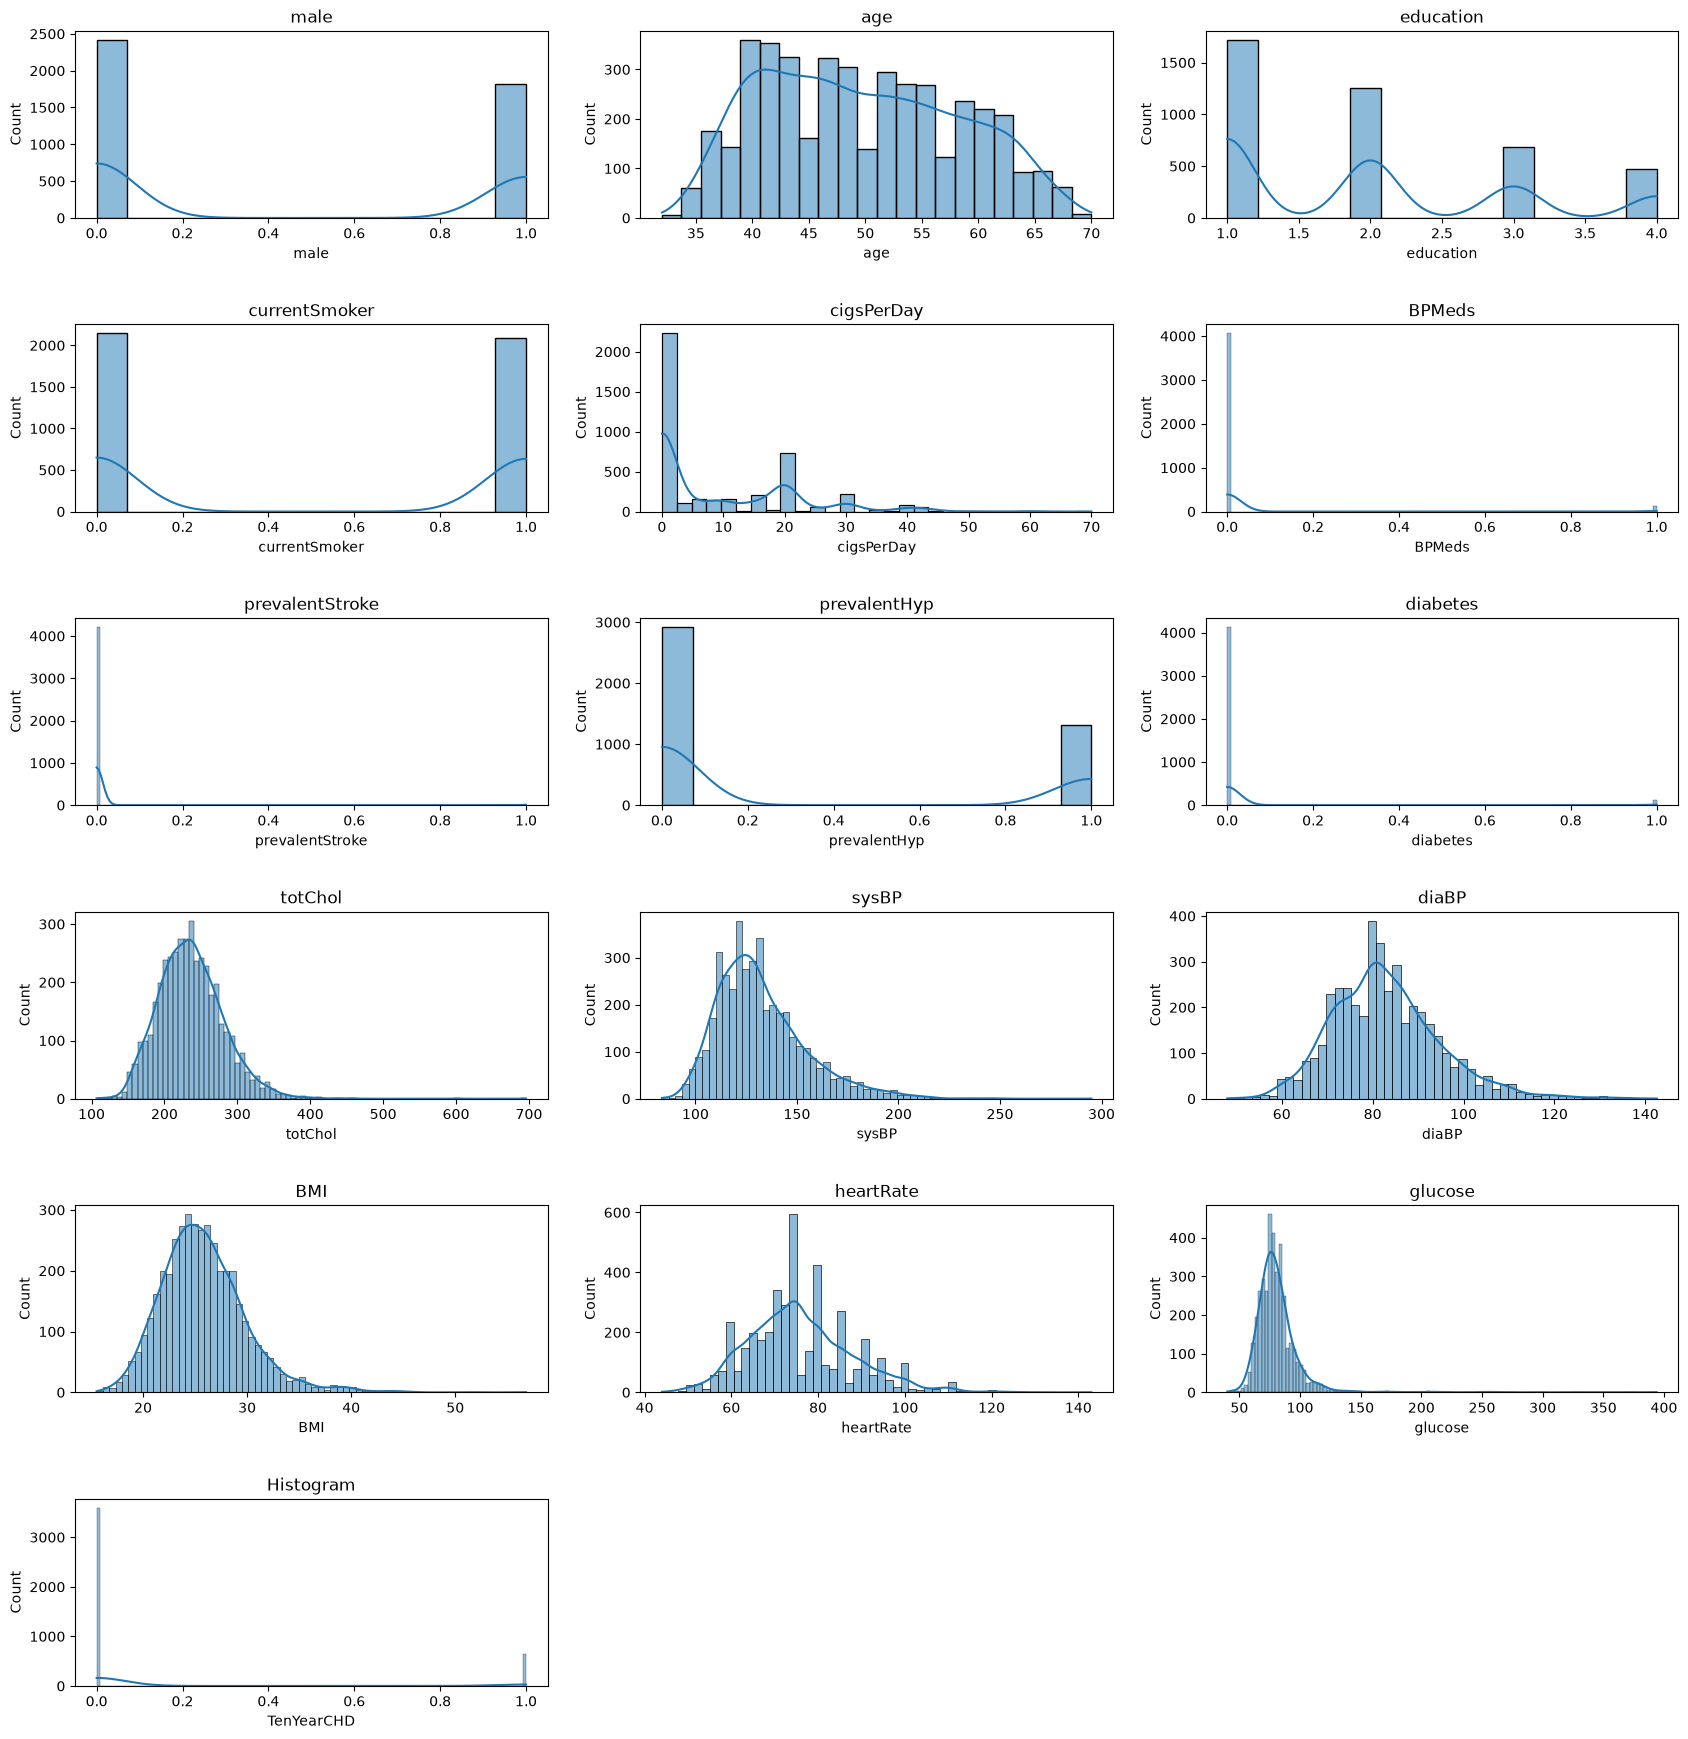

In [13]:
kolom = df.select_dtypes(include=['number'])
plt.figure(figsize=(17, 20))

for i, col in enumerate(kolom, start=1):
    plt.subplot(7, 3, i)
    sns.histplot(data=df[col], kde=True)
    plt.title(col)
plt.tight_layout(h_pad=3.0, w_pad=2.0)
plt.title('Histogram')
plt.show()

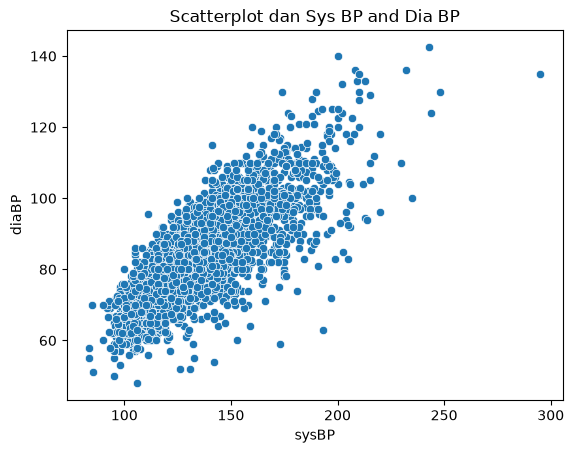

In [14]:
sns.scatterplot(data=df, x='sysBP', y='diaBP')
plt.title('Scatterplot dan Sys BP and Dia BP')
plt.show()


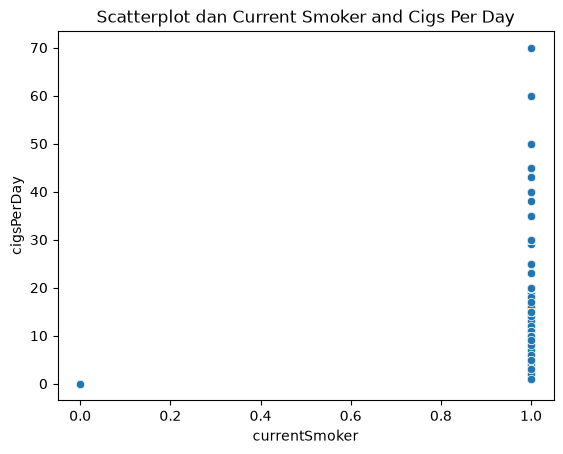

In [15]:
sns.scatterplot(data=df, x='currentSmoker', y='cigsPerDay')
plt.title('Scatterplot dan Current Smoker and Cigs Per Day')
plt.show()

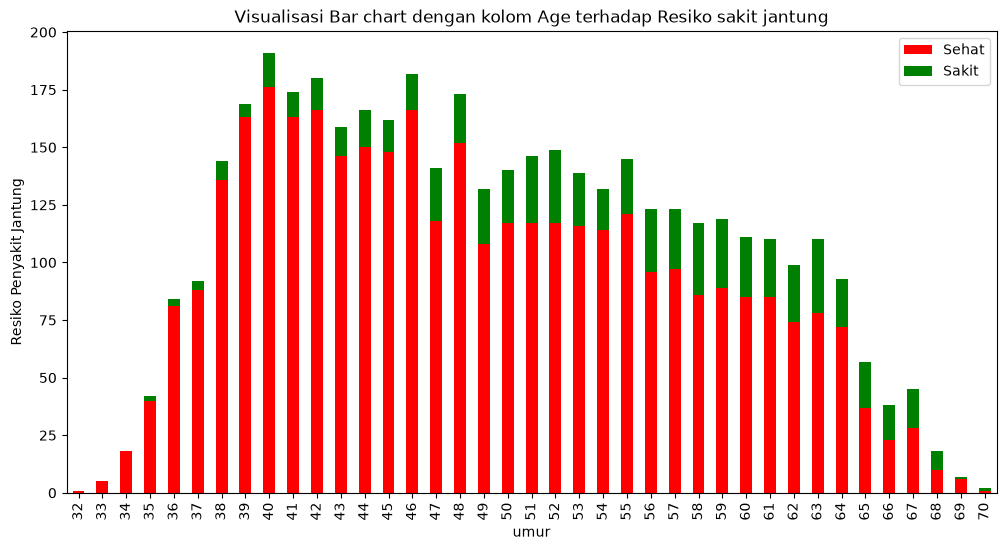

In [16]:
tbel = pd.crosstab(df['age'],df['TenYearCHD'])

tbel.plot(kind='bar',stacked=True,color=['red','green'], figsize=(12,6))

plt.title("Visualisasi Bar chart dengan kolom Age terhadap Resiko sakit jantung")
plt.xlabel("umur")
plt.ylabel("Resiko Penyakit Jantung")
plt.legend(labels = ['Sehat','Sakit'])
plt.show()

Terlihat bahwa semakin tua umur semakin besar juga resiko penyakit jantung ketika usia mendekati 50 sampai ke usia 70

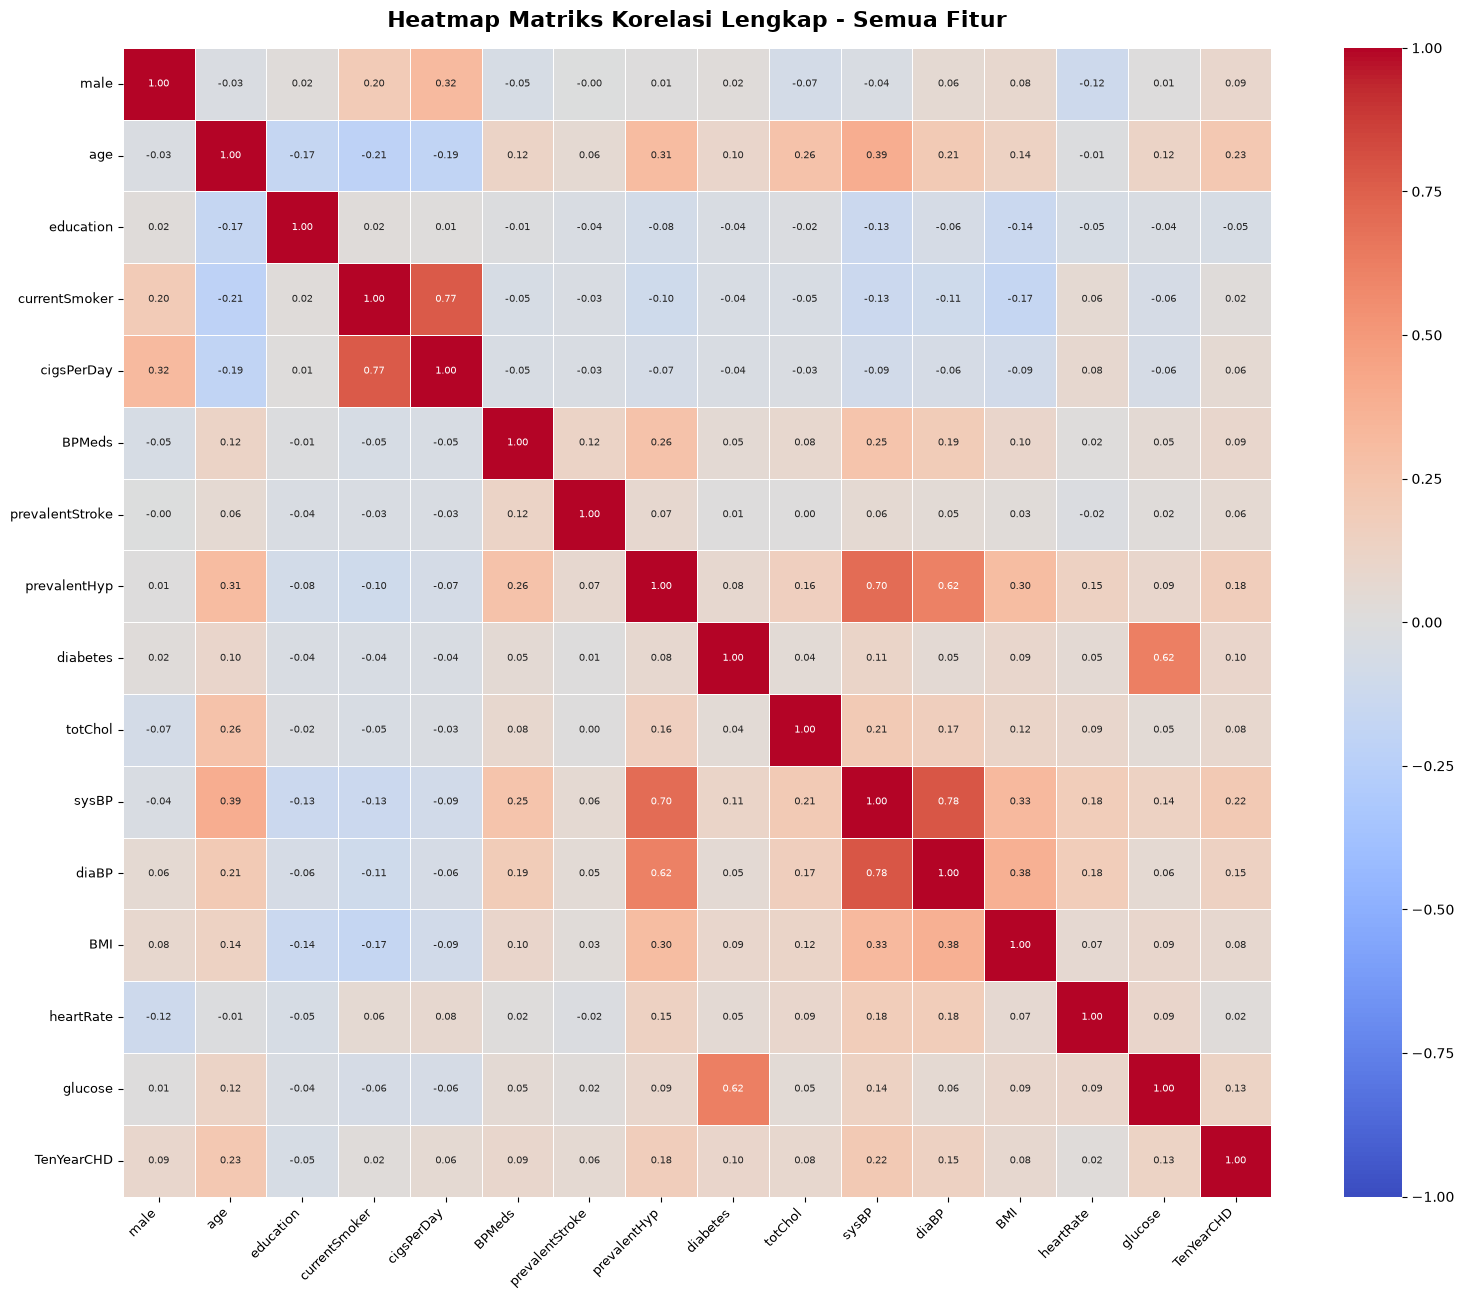

In [17]:
df_corr = df.select_dtypes(include=['int64', 'float64']).corr()
plt.figure(figsize=(16, 13))
sns.heatmap(
    df_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1, vmax=1,
    linewidths=0.5,
    linecolor='white',
    square=True,
    annot_kws={'size': 7.5}
)
plt.title('Heatmap Matriks Korelasi Lengkap - Semua Fitur', fontsize=16, pad=15, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

# **4. Data Preprocessing**

In [18]:
cek_skala_awal = pd.DataFrame({
    'Min':df.min(),
    'Max':df.max(),
    'Rentang':df.max() - df.min(),
    'Mean':df.mean(),
    'Std': df.std()
})

cek_skala_awal

,Min,Max,Rentang,Mean,Std
male,0.00,1.0,1.00,0.429212,0.495022
age,32.00,70.0,38.00,49.584946,8.572160
education,1.00,4.0,3.00,1.978950,1.019791
currentSmoker,0.00,1.0,1.00,0.494101,0.500024
cigsPerDay,0.00,70.0,70.00,9.003089,11.920094
BPMeds,0.00,1.0,1.00,0.029630,0.169584
prevalentStroke,0.00,1.0,1.00,0.005899,0.076587
prevalentHyp,0.00,1.0,1.00,0.310524,0.462763
diabetes,0.00,1.0,1.00,0.025720,0.158316
totChol,107.00,696.0,589.00,236.721585,44.590334


In [19]:
df['BPMeds'] = df['BPMeds'].fillna(df['BPMeds'].mode()[0]).astype(int)
df['education'] = df['education'].fillna(df['education'].median()).astype(int)

In [20]:
median_smoker = df[df['currentSmoker'] == 1]['cigsPerDay'].median()
df['cigsPerDay'] = df['cigsPerDay'].fillna(median_smoker)

In [21]:
cont_cols = ['totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose']
df[cont_cols] = df[cont_cols].fillna(df[cont_cols].median())

In [22]:
df.isnull().sum().sum()

np.int64(0)

In [23]:
df.head()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4,0,0.0,0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2,0,0.0,0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1,1,20.0,0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3,1,30.0,0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3,1,23.0,0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [24]:
cols = df.select_dtypes(include='float64').columns

Q1 = df[cols].quantile(0.25)
Q3 = df[cols].quantile(0.75)

IQR =  Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier = ((df[cols] < batas_bawah) | (df[cols] > batas_atas)).sum()
print("Jumlah outlier per kolom:")
print(outlier)

Jumlah outlier per kolom:
cigsPerDay     12
totChol        57
sysBP         126
diaBP          81
BMI            97
heartRate      76
glucose       262
dtype: int64


In [25]:
for col in cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    bb = q1 - 1.5 * iqr
    ba = q3 + 1.5 * iqr
    df[col] = df[col].clip(lower=bb, upper=ba)

Q1 = df[cols].quantile(0.25)
Q3 = df[cols].quantile(0.75)
IQR = Q3 - Q1
outlier = ((df[cols] < (Q1 - 1.5 * IQR)) | (df[cols] > (Q3 + 1.5 * IQR))).sum()
print('Jumlah outlier tiap kolom setelah clipping:\n', outlier)

Jumlah outlier tiap kolom setelah clipping:
 cigsPerDay    0
totChol       0
sysBP         0
diaBP         0
BMI           0
heartRate     0
glucose       0
dtype: int64


## **5. Modelling** 

In [26]:
X = df.drop(columns=['TenYearCHD','diaBP','currentSmoker'])
y = df[['TenYearCHD']]

In [27]:
X_cek = X
invers_cek = np.linalg.inv(X_cek.corr().values)

cek_vif = pd.DataFrame ({
    'Fitur' : X_cek.columns,
    'vif' : np.diag(invers_cek)
}).sort_values(by='vif',ascending=False).reset_index(drop=True)

cek_vif

,Fitur,vif
0,sysBP,2.320640
1,prevalentHyp,2.100606
2,age,1.332807
3,cigsPerDay,1.200670
4,BMI,1.179949
5,male,1.179615
6,totChol,1.115827
7,glucose,1.107464
8,BPMeds,1.098276
9,heartRate,1.095680


In [28]:
def split_data(X, y, train_size=0.8, random_state=42):
    np.random.seed(random_state)
    idx = np.random.permutation(len(X))
    split_ratio = int(train_size * len(X))
    X_train, X_test = X.iloc[idx[:split_ratio]], X.iloc[idx[split_ratio:]]
    y_train, y_test = y.iloc[idx[:split_ratio]], y.iloc[idx[split_ratio:]]
    return X_train, X_test, y_train, y_test

X_train, X_test, y_train, y_test = split_data(X, y)

Hanya pakai train dan test di karenakan memang adanya imba pada target

In [29]:
mean = np.mean(X_train, axis=0)
std = np.std(X_train, axis=0)

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

X_train = np.array(X_train)
X_test = np.array(X_test)
y_train = np.array(y_train).reshape(-1)
y_test = np.array(y_test).reshape(-1)

m,n = X_train.shape

In [30]:
def sigmoid(z):
    return 1 /(1+np.exp (-z))

In [31]:
def cost_function(X,y,w,b):
    # menghitung seberapa besar total kesalahan
    m, n = X.shape
    cost_sum = 0
    for i in range (m):
        z =np.dot(w,X[i]) + b
        g = sigmoid(z)

        cost_sum += -y[i] * np.log(g) - (1 - y[i]) * np.log(1-g)
    return (1/m) * cost_sum

In [32]:
def gradient_function(X, y, w, b):
    m, n = X.shape
    #menyiapkan wadah dengan nilai 0
    grad_w = np.zeros(n)
    grad_b = 0

    for i in range(m):
        z = np.dot(w, X[i]) + b
        g = sigmoid(z)

        # Tambahan bobot denda 3x lipat untuk pasien sakit
        bobot = 5.5 if y[i] == 1 else 1.0
        err = (g - y[i]) * bobot

        grad_b += err
        for j in range(n):
            grad_w[j] += err * X[i, j]

    grad_b = (1 / m) * grad_b
    grad_w = (1 / m) * grad_w

    return grad_b, grad_w

In [33]:
def gradient_desc(X,y,alpha,iterasi):
    #mencari parameter w dan b sampai error mengecil dan sampai batas iterasi
    m, n = X.shape
    w = np.zeros(n)
    b = 0

    for i in range (iterasi):
        grad_b,grad_w = gradient_function(X,y,w,b)

        # update parametr
        w = w - alpha * grad_w
        b = b - alpha * grad_b

        if i % 200 == 0:
            print(f"iterasi{i}: cost{cost_function(X,y,w,b)}")

    return w,b

In [34]:
def predict(X,w,b):
    m, n = X.shape
    preds = np.zeros(m)

    for i in range(m):
        z = np.dot(w,X[i]) + b
        g = sigmoid(z)

        # menentukan kelas hasil probabilitas denga thresholding
        preds[i] = 1 if g >= 0.5 else 0

    return preds

## **6.0 Evaluasi Model**

In [35]:
learning_rate = 0.01
iterasi = 1000

final_w, final_b = gradient_desc(X_train,y_train,learning_rate,iterasi)

prediksi = predict(X_train, final_w,final_b)
akurasi =  np.mean(prediksi == y_train) * 100
print(akurasi)

iterasi0: cost0.6924429413726554


iterasi200: cost0.65073177714721
iterasi400: cost0.634075962819622
iterasi600: cost0.6238182468902254
iterasi800: cost0.617762901817155
67.07964601769912


In [36]:
y_pred = predict(X_test, final_w, final_b)
y_true = y_test

TP = np.sum((y_true == 1) & (y_pred == 1))
TN = np.sum((y_true == 0) & (y_pred == 0))
FP = np.sum((y_true == 0) & (y_pred == 1))
FN = np.sum((y_true == 1) & (y_pred == 0))

presisi = (TP / (TP + FP)) * 100 if (TP + FP) > 0 else 0
recall = (TP / (TP + FN)) * 100 if (TP + FN) > 0 else 0
f1 = (2 * presisi * recall) / (presisi + recall) if (presisi + recall) > 0 else 0
    

print(f"Precision : {presisi:}")
print(f"Recall    : {recall:}")
print(f"F1-Score  : {f1:}")

Precision : 28.3987915407855
Recall    : 73.4375
F1-Score  : 40.95860566448802


**Ketika Bobot menggunakan 3.0**

Akurasi : 78.77%

Precision : 33.33%

Recall    : 40.62%

F1-Score  : 36.62%

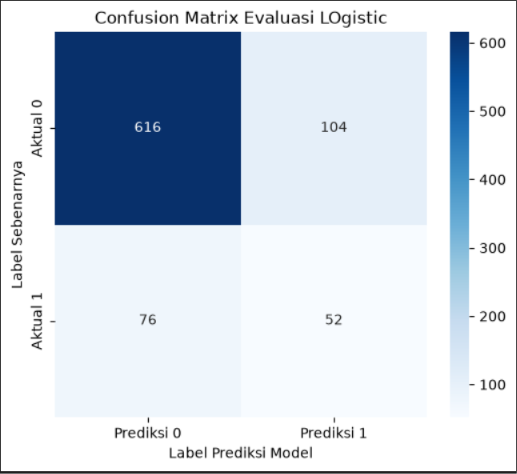

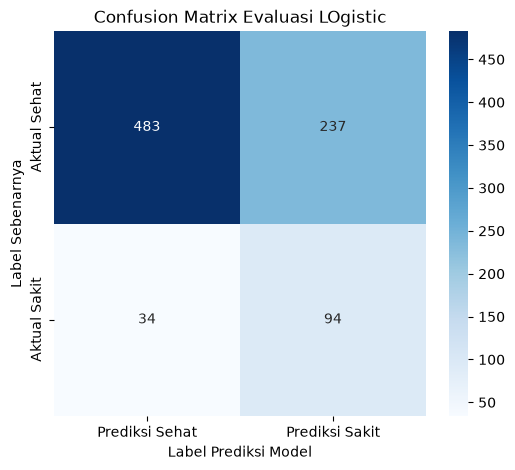

In [37]:
cm = np.array([[TN,FP] , [FN,TP]])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues',
    xticklabels=['Prediksi Sehat', 'Prediksi Sakit'],
    yticklabels=['Aktual Sehat', 'Aktual Sakit']
)
plt.title('Confusion Matrix Evaluasi LOgistic', fontsize=12)
plt.ylabel('Label Sebenarnya')
plt.xlabel('Label Prediksi Model')
plt.show()

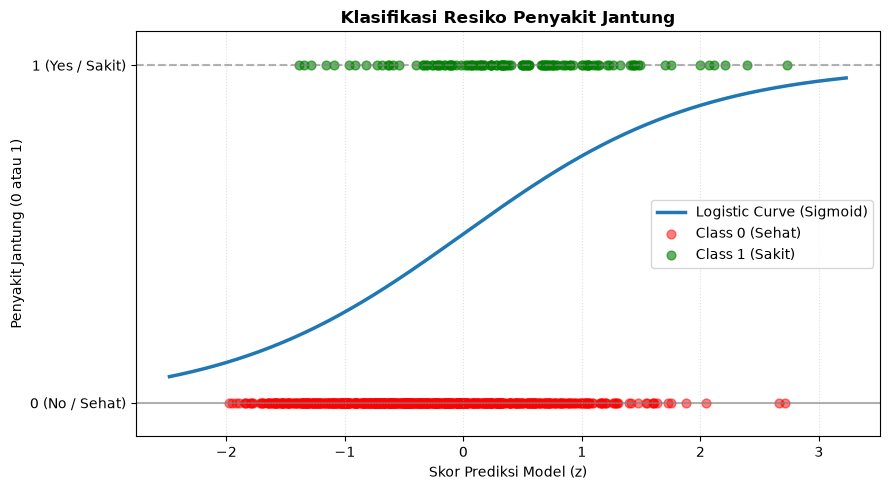

In [38]:
z_test = np.dot(X_test, final_w) + final_b

z_curve = np.linspace(z_test.min() - 0.5, z_test.max() + 0.5, 300)
prob_curve = sigmoid(z_curve)

plt.figure(figsize=(9, 5))
plt.plot(z_curve, prob_curve, color='#1f77b4', linewidth=2.5, label='Logistic Curve (Sigmoid)')

plt.scatter(z_test[y_test == 0], np.zeros(np.sum(y_test == 0)), color='red', alpha=0.5, s=40, label='Class 0 (Sehat)')

plt.scatter(z_test[y_test == 1], np.ones(np.sum(y_test == 1)), color='green', alpha=0.6, s=40, label='Class 1 (Sakit)')

plt.axhline(y=1, color='gray', linestyle='--', alpha=0.6)
plt.axhline(y=0, color='gray', linestyle='-', alpha=0.6)
plt.yticks([0, 1], ['0 (No / Sehat)', '1 (Yes / Sakit)'])

plt.title('Klasifikasi Resiko Penyakit Jantung', fontsize=12, fontweight='bold')
plt.xlabel('Skor Prediksi Model (z)')
plt.ylabel('Penyakit Jantung (0 atau 1)')
plt.ylim(-0.1, 1.1)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.4)
plt.tight_layout()
plt.show()

## **7.0 GUI**

In [39]:
# ---- peta kategori (sesuai kolom dataset framingham) ----
BINARY = {"no": 0, "yes": 1}
INV_BINARY = {v: k for k, v in BINARY.items()}
GENDER = {"female": 0, "male": 1}
INV_GENDER = {v: k for k, v in GENDER.items()}

COLUMNS = X.columns.tolist()

# akurasi model logistic regression pada data uji
AKURASI = np.mean(predict(X_test, final_w, final_b) == y_test) * 100

def _prediksi(nilai):
    """Terima dict {kolom: angka}, kembalikan label 0/1 memakai model logistic regression."""
    v = np.array([nilai[c] for c in COLUMNS], dtype=float)
    v = (v - mean.values) / std.values
    g = sigmoid(np.dot(final_w, v) + final_b)
    return 1 if g >= 0.5 else 0

def _cari_contoh(target):
    """Cari 1 baris nyata yang berlabel `target` (1=sakit, 0=sehat)."""
    subset = df[df["TenYearCHD"] == target]
    kandidat = subset.sample(n=min(300, len(subset)), random_state=1)
    for _, baris in kandidat.iterrows():
        if _prediksi({c: float(baris[c]) for c in COLUMNS}) == target:
            return baris
    return None

CONTOH_YA = _cari_contoh(1)
CONTOH_TIDAK = _cari_contoh(0)

class Aplikasi(tk.Tk):
    def __init__(self):
        super().__init__()
        self.title('Prediksi Risiko Penyakit Jantung (Logistic Regression)')
        self.geometry('560x820')
        self.resizable(False, False)
        self._build_form()

    def _build_form(self):
        header = tk.Frame(self, bg="#1f4e79", height=70)
        header.pack(fill="x")
        tk.Label(header, text="Prediksi Risiko Penyakit Jantung", bg="#1f4e79",
                 fg="white", font=("Segoe UI", 15, "bold")).pack(pady=(12, 0))
        tk.Label(header, text="Metode Logistic Regression", bg="#1f4e79",
                 fg="#cfe2f3", font=("Segoe UI", 10)).pack(pady=(0, 12))

        form = ttk.Frame(self, padding=20)
        form.pack(fill="both", expand=True)
        form.columnconfigure(1, weight=1)

        # definisi tiap field: (tipe, label, nilai default)
        self.entries, self.combos = {}, {}
        rows = {
            "male":            ("combo", "Jenis Kelamin", list(GENDER.keys())),
            "age":             ("entry", "Usia (tahun)", "50"),
            "education":       ("entry", "Tingkat Pendidikan (1-4)", "2"),
            "cigsPerDay":      ("entry", "Rokok per Hari (batang)", "0"),
            "BPMeds":          ("combo", "Obat Tekanan Darah", list(BINARY.keys())),
            "prevalentStroke": ("combo", "Riwayat Stroke", list(BINARY.keys())),
            "prevalentHyp":    ("combo", "Riwayat Hipertensi", list(BINARY.keys())),
            "diabetes":        ("combo", "Diabetes", list(BINARY.keys())),
            "totChol":         ("entry", "Kolesterol Total (mg/dL)", "230"),
            "sysBP":           ("entry", "Tekanan Darah Sistolik (mmHg)", "125"),
            "BMI":             ("entry", "BMI (kg/m2)", "25"),
            "heartRate":       ("entry", "Denyut Jantung (bpm)", "75"),
            "glucose":         ("entry", "Glukosa (mg/dL)", "80"),
        }

        r = 0
        for col, (kind, label, val) in rows.items():
            ttk.Label(form, text=label, font=("Segoe UI", 10)).grid(
                row=r, column=0, sticky="w", pady=5, padx=(0, 10))
            if kind == "entry":
                e = ttk.Entry(form, font=("Segoe UI", 10))
                e.insert(0, val)
                e.grid(row=r, column=1, sticky="ew", pady=5)
                self.entries[col] = e
            else:
                c = ttk.Combobox(form, values=val, state="readonly", font=("Segoe UI", 10))
                c.current(0)
                c.grid(row=r, column=1, sticky="ew", pady=5)
                self.combos[col] = c
            r += 1

        # baris tombol 1: aksi utama
        btns = ttk.Frame(form)
        btns.grid(row=r, column=0, columnspan=2, sticky="ew", pady=(16, 4))
        btns.columnconfigure((0, 1, 2), weight=1)
        ttk.Button(btns, text="Isi Otomatis", command=self.on_autofill).grid(
            row=0, column=0, sticky="ew", padx=(0, 5), ipady=6)
        ttk.Button(btns, text="Prediksi", command=self.on_predict).grid(
            row=0, column=1, sticky="ew", padx=5, ipady=6)
        ttk.Button(btns, text="Reset", command=self.on_reset).grid(
            row=0, column=2, sticky="ew", padx=(5, 0), ipady=6)

        # baris tombol 2: contoh pasien
        btns2 = ttk.Frame(form)
        btns2.grid(row=r + 1, column=0, columnspan=2, sticky="ew", pady=(0, 6))
        btns2.columnconfigure((0, 1), weight=1)
        ttk.Button(btns2, text="Contoh: Berisiko Sakit",
                   command=self.on_contoh_ya).grid(
            row=0, column=0, sticky="ew", padx=(0, 5), ipady=6)
        ttk.Button(btns2, text="Contoh: Tidak Berisiko",
                   command=self.on_contoh_tidak).grid(
            row=0, column=1, sticky="ew", padx=(5, 0), ipady=6)

        # label hasil
        self.result_var = tk.StringVar(value="Masukkan data lalu tekan Prediksi.")
        self.result_label = tk.Label(form, textvariable=self.result_var,
                                     font=("Segoe UI", 12, "bold"), bg="#f2f2f2",
                                     fg="#333333", wraplength=480, justify="center", pady=16)
        self.result_label.grid(row=r + 2, column=0, columnspan=2, sticky="ew", pady=(8, 0))

        tk.Label(self, text=f"Model siap - akurasi uji {AKURASI:.2f}%",
                 font=("Segoe UI", 9), fg="#666666").pack(side="bottom", pady=6)

    # ---------------------- aksi tombol ----------------------
    def _kumpulkan_input(self):
        nilai = {}
        for col, entry in self.entries.items():
            teks = entry.get().strip().replace(",", ".")
            if teks == "":
                raise ValueError(f"Field '{col}' tidak boleh kosong.")
            try:
                nilai[col] = float(teks)
            except ValueError:
                raise ValueError(f"Field '{col}' harus berupa angka.")
        for col, combo in self.combos.items():
            nilai[col] = GENDER[combo.get()] if col == "male" else BINARY[combo.get()]
        return nilai

    def _isi_form(self, baris):
        for col, entry in self.entries.items():
            entry.delete(0, tk.END)
            v = float(baris[col])
            entry.insert(0, str(int(v)) if v.is_integer() else str(v))
        self.combos["male"].set(INV_GENDER[int(baris["male"])])
        self.combos["BPMeds"].set(INV_BINARY[int(baris["BPMeds"])])
        self.combos["prevalentStroke"].set(INV_BINARY[int(baris["prevalentStroke"])])
        self.combos["prevalentHyp"].set(INV_BINARY[int(baris["prevalentHyp"])])
        self.combos["diabetes"].set(INV_BINARY[int(baris["diabetes"])])

    def _tampilkan_hasil(self):
        label = _prediksi(self._kumpulkan_input())
        if label == 1:
            self.result_var.set("PREDIKSI: YA - pasien berisiko mengalami penyakit jantung")
            self.result_label.configure(bg="#f8d7da", fg="#a12622")
        else:
            self.result_var.set("PREDIKSI: TIDAK - pasien kemungkinan tidak berisiko")
            self.result_label.configure(bg="#d9ead3", fg="#1e6b34")

    def on_autofill(self):
        self._isi_form(df.sample(n=1).iloc[0])
        self.result_var.set("Data contoh terisi otomatis. Tekan Prediksi untuk melihat hasil.")
        self.result_label.configure(bg="#f2f2f2", fg="#333333")

    def on_contoh_ya(self):
        if CONTOH_YA is None:
            messagebox.showwarning("Info", "Tidak menemukan contoh pasien berisiko.")
            return
        self._isi_form(CONTOH_YA)
        self._tampilkan_hasil()

    def on_contoh_tidak(self):
        if CONTOH_TIDAK is None:
            messagebox.showwarning("Info", "Tidak menemukan contoh pasien tidak berisiko.")
            return
        self._isi_form(CONTOH_TIDAK)
        self._tampilkan_hasil()

    def on_predict(self):
        try:
            self._tampilkan_hasil()
        except ValueError as exc:
            messagebox.showwarning("Input tidak valid", str(exc))

    def on_reset(self):
        default = {"age": "50", "education": "2", "cigsPerDay": "0", "totChol": "230",
                   "sysBP": "125", "BMI": "25", "heartRate": "75", "glucose": "80"}
        for col, entry in self.entries.items():
            entry.delete(0, tk.END)
            entry.insert(0, default.get(col, "0"))
        for combo in self.combos.values():
            combo.current(0)
        self.result_var.set("Masukkan data lalu tekan Prediksi.")
        self.result_label.configure(bg="#f2f2f2", fg="#333333")

# ---- jalankan aplikasi ----
app = Aplikasi()
app.mainloop()


## **8.0 Conclution**

### 8.1 Kesimpulan Dataset

* **Ukuran data:** Dataset ini tergolong cukup besar dengan total 67808, 4238 baris dan 16 kolom.

* **Kelengkapan data dan duplikasi:** Di dalam dataset ini terdapat 645 data kosong dan terdapat beberapa outlier namun dataset ini tidak terdapat data duplikat

* **Sebaran data:** Persebaran data pada kolom target tidak seimbang 3594 orang yang terindikasi sehat dan hanya ada 644 orang yang terindikasi sakit jantung

* **Korelasi Data:** Terindikasi adanya multikolinearitas antara fitur rokok perhari dan status perokok begitu juga dengan sysBP dan diaBP


### 8.2 Keputusan Tahap Pre Processing

* **Missing Values**: Mengisi data dengan kolom yang bersifat kontinu dengan median dan juga kolom yang bersifat diskrit dengan modus atau pun modus.

* **Encoding Data**: Melakukan encoding pada kolom biner yang bernilai float agar menjadi tipe data int

* **Penanganan outlier**: 
Melakukan capping pada data kontinu dikarenakan terlalu banyak sehingga tidak bisa di hapus dan metode capping jauh lebih aman.

* **Imbalanced data** : Mengatasi data imbalanced pada kolom target dengan melakukan pembobotan kelas dengan memberikan denda pada model menjadi 5.5x lipat agar model lebih berhati - hati dalam memprediksi target yang tidak seimbang

### 8.3 Kesimpulan Algoritma

* **Keputusan Pemilihan:** Memilih Binary Logistic Regression karena model ini sangat cocok dengan fitur target yang benilai ya atau tidak untuk klasifikasi
* **Kelebihan:**
  1. Output yang di hasilkan berupa probabilitas 0 - 1 menggunakan sigmoid
  2. Mudah di baca dan di interpretasikan
* **Kekurangan:**
  1. Rentan terhadap multikolinearitas dimana antar variabel independen memiliki hubungan yang kuat, sehingga akan mempengaruhi model
  2. Sensitif terhadap outlier yang bisa merusak garis prediksi
  3. Sensitif pada data yang tidak seimbang
  4. Rentan terhadap overfitting
* **Cara Mengatasi:**
  1. Mengamati menggunakan vif atau heatmap korelasi, dan menghapus salah satu kolom yang memiliki relasi kuat dengan fitur lain
  2. Mengamati outlier menggunakan iqr atau z score sebelum ke modeling
  3. Gunakan Pembobotan kelas agar tidak mengabaikan kelas minoritas
  4. Menambah penalti penahan bobot berupa regularisasi L1 atau Lasso


### 8.4 Hasil Analisis Evaluasi

1. **Akurasi Model:**
   Akurasi model Logistic Regression mencapai 68.04%, menunjukkan performa yang cukup baik dan realistis dalam memprediksi risiko penyakit jantung pada data yang tidak seimbang.


2. **Precision:**
   Nilai Precision sebesar 28.31%, membuktikan bahwa 28.31% pasien yang diprediksi berisiko tinggi memang terbukti positif menderita penyakit jantung

3. **Recall:**
  Nilai Recall sebesar 73.44%, membuktikan model berhasil mendeteksi mayoritas pasien yang benar-benar sakit jantung dengan sedikit kasus yang terlewat
  
3. **F1-Score:**
  Nilai F1-Score sebesar 40.87%, membuktikan adanya keseimbangan yang jauh lebih baik antara Precision dan Recall setelah dilakukan penanganan data imbalanced.